# Clinical Transformer for Survival - Token por Visita

Notebook hermano de `grud_student_extension.ipynb`. Aqui construimos un
**Transformer Encoder** que predice riesgo de cancer de pulmon a 5 anos a
partir de secuencias longitudinales irregulares de laboratorio.

A diferencia del paper STraTS original - donde cada *triple* (lab, valor, tiempo)
es un token - aqui **cada visita es un token** que fusiona:

1. los valores de los 23 labs medidos en esa visita,
2. la mascara de observacion (que se midio - clave porque los labs ausentes son 0),
3. la **codificacion continua del tiempo** (Time2Vec / STraTS) sobre los anos
   transcurridos desde la edad de entrada a la cohorte (posicion absoluta de la visita),
4. (opcional) el embedding ICD-10 de los diagnosticos registrados en esa visita
   (en el `build_sequences.py` ya se mergean labs + condiciones a un mismo `times[i]`),
5. la covariable estatica `sex_male` (proyectada y broadcasteada a todas las visitas).

La salida se optimiza con la **perdida parcial de Cox** reutilizando los modulos
de `workflow/scripts/` ya implementados para GRU-D (`dataset`, `engine`, `loss`,
`eval`, `model.TimeAwareGRUD` para comparativa).

**Compatibilidad con GRU-D:** el modelo expone la misma firma y el mismo return
que `TimeAwareGRUD`, por lo que `run_raw_loss_epoch_icd`, `collect_raw_outputs`
y `cox_ph_loss` se importan **sin modificarlos** - comparativa justa.

> Che et al. (2018) GRU-D y Tipirneni et al. (2022) STraTS - *Self-attention for*
> *irregularly sampled time series*.
> https://doi.org/10.1038/s41598-018-24271-9
> https://arxiv.org/abs/2107.12330


In [9]:
# -- Google Colab: montar Drive solo si estamos en Colab --
try:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip install -q lifelines
except ImportError:
    # Ejecución local (VS Code / Jupyter local)
    pass

# -- Imports estándar --
import copy
import pickle
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from lifelines.utils import concordance_index
from torch.utils.data import DataLoader, WeightedRandomSampler

# -- Resolver la ruta a workflow/scripts de forma robusta (local y Colab) --
DRIVE_BASE = Path('/content/drive/MyDrive/TFM/us-mulcia-2026-ramon')
SCRIPTS_CANDIDATES = [
    Path.cwd().parent / 'workflow' / 'scripts',                          # Local: si ejecutas desde /sandbox/
    Path.cwd() / 'workflow' / 'scripts',                                 # Local: si ejecutas desde la raíz del repo
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'workflow' / 'scripts',           # Colab
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'tfm-mulcia-2025-1' / 'workflow' / 'scripts', # Colab alt
    Path('/content/tfm-mulcia-2025-1/workflow/scripts'),                 # Colab directo
    Path('/content/workflow/scripts'),
]

SCRIPTS_DIR = next((p.resolve() for p in SCRIPTS_CANDIDATES if p.exists()), None)
if SCRIPTS_DIR is None:
    raise FileNotFoundError(f"No se encontró 'workflow/scripts'. Comprueba las rutas: {SCRIPTS_CANDIDATES}")

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

# -- Importar los módulos del proyecto --
from dataset import (
    RawSequenceDatasetWithICD,
    raw_pad_collate_with_icd,
    load_sequences,
)
from engine import (
    run_raw_loss_epoch_icd,
    collect_raw_outputs,
    compute_baseline_hazard,
)
from loss import cox_ph_loss
from model import TimeAwareGRUD  # solo para la comparativa final

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Scripts dir: {SCRIPTS_DIR}')


Device: cpu
Scripts dir: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\workflow\scripts


In [10]:
# -- Cohorte / landmark --
LANDMARK_AGE     = 55.0
INDEX_AGE        = 18.0
HORIZON          = 5.0
MAX_SEQ_LEN      = 200
LANDMARK_TRAIN   = list(range(45, 71))   # entrenamos en todos los landmarks
LANDMARK_VAL     = list(range(45, 71))   # y evaluamos en todos

# -- Modelo (Transformer) --
D_MODEL           = 64
NHEAD             = 4
NUM_LAYERS        = 3
DIM_FEEDFORWARD   = 128
DROPOUT           = 0.2    # mas alto que GRU-D (0.1): transformer tiene mas parametros
USE_ICD           = True
ICD_DIM           = 16     # paridad con EMBED_DIM de GRU-D

# -- Entrenamiento --
BATCH_SIZE        = 256
MAX_EPOCHS        = 30
PATIENCE          = 5
LEARNING_RATE     = 1e-4    # mas bajo que GRU-D (5e-4): transformer tiene mas params
WEIGHT_DECAY      = 1e-4
AGE_WEIGHT_GAMMA  = 1.0
EVENT_OVERSAMPLE  = 2.0

# -- Paths (compartidos con el notebook GRU-D) --
DATA_DIR_CANDIDATES = [ 
    Path.cwd().parent / 'results' / 'train',                          # Local: si ejecutas desde /sandbox/
    Path.cwd() / 'results' / 'train',       
    DRIVE_BASE / 'data_tmp',
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'data_tmp',
]

DATA_VAL_CANDIDATES = [ 
    Path.cwd().parent / 'results' / 'val',                          # Local: si ejecutas desde /sandbox/
    Path.cwd() / 'results' / 'val',       
    DRIVE_BASE / 'data_tmp',
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'data_tmp',
]
DATA_TRAIN_DIR = next((p for p in DATA_DIR_CANDIDATES if (p / 'sequences_train.pkl').exists()),
                DATA_DIR_CANDIDATES[0])
DATA_VAL_DIR = next((p for p in DATA_VAL_CANDIDATES if (p / 'sequences_train.pkl').exists()),
                DATA_VAL_CANDIDATES[0])
OUT_DIR = Path.cwd() / 'results' / 'transformer'
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'DATA_TRAIN_DIR: {DATA_TRAIN_DIR}')
print(f'DATA_VAL_DIR: {DATA_VAL_DIR}')
print(f'OUT_DIR : {OUT_DIR}')


DATA_TRAIN_DIR: c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\results\train
DATA_VAL_DIR: c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\results\val
OUT_DIR : c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\sandbox\results\transformer


In [11]:
# -- Cargar secuencias (mismos pickles que GRU-D) --
sequences_train, lab_codes, cohort_train = load_sequences(DATA_TRAIN_DIR / 'sequences.pkl')
sequences_val,   _,         cohort_val   = load_sequences(DATA_VAL_DIR / 'sequences.pkl')
lab_dim = len(lab_codes)

print(f'{lab_dim} lab features')
print(f'Train: {len(sequences_train)} pacientes  |  event_rate={cohort_train["event"].mean():.3f}')
print(f'Val:   {len(sequences_val)} pacientes    |  event_rate={cohort_val["event"].mean():.3f}')

# -- Vocabulario ICD-10 (idempotente con train.py y el notebook GRU-D) --
all_icd_codes = set()
for pid, seq in sequences_train.items():
    for step_codes in seq['codes']:
        for code in step_codes:
            all_icd_codes.add(code)
code_to_idx = {code: i + 1 for i, code in enumerate(sorted(all_icd_codes))}
vocab_size = len(code_to_idx) + 1
print(f'Vocabulario ICD-10: {len(code_to_idx)} codigos unicos. vocab_size = {vocab_size}')

# -- Datasets (reusamos RawSequenceDatasetWithICD sin tocarlo) --
train_dataset = RawSequenceDatasetWithICD(
    sequences=sequences_train,
    cohort_df=cohort_train,
    landmark_ages=LANDMARK_TRAIN,
    index_age=INDEX_AGE,
    code_to_idx=code_to_idx,
    max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)
val_dataset = RawSequenceDatasetWithICD(
    sequences=sequences_val,
    cohort_df=cohort_val,
    landmark_ages=LANDMARK_VAL,
    index_age=INDEX_AGE,
    code_to_idx=code_to_idx,
    max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)
print(f'Train: N={len(train_dataset)}  event_rate={train_dataset.event_rate:.3f}  mean_len={train_dataset.mean_seq_len:.1f}')
print(f'Val:   N={len(val_dataset)}    event_rate={val_dataset.event_rate:.3f}    mean_len={val_dataset.mean_seq_len:.1f}')

# -- DataLoaders con event oversampling (igual que GRU-D) --
sample_weights = [EVENT_OVERSAMPLE if f == 1 else 1.0 for f in train_dataset.event_flags]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
    collate_fn=raw_pad_collate_with_icd,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=raw_pad_collate_with_icd,
)


23 lab features
Train: 12069 pacientes  |  event_rate=0.036
Val:   3018 pacientes    |  event_rate=0.036
Vocabulario ICD-10: 119 codigos unicos. vocab_size = 120
Train: N=202672  event_rate=0.042  mean_len=5.1
Val:   N=49765    event_rate=0.040    mean_len=5.2


## Modelo - `ClinicalTransformerSurvival`

Cada visita se proyecta a un token denso de dimension `d_model = 64` sumando:

1. **Labs**: $E_{\text{labs}} \in \mathbb{R}^{23 \times d}$, token = $x_t \cdot E_{\text{labs}}$
2. **Mascara**: `Linear(23 -> d)` sobre $m_t$ (informa que se midio en la visita - critico porque $x_t = 0$ cuando el lab no se midio)
3. **Tiempo continuo (Time2Vec / STraTS)** sobre $\tau_t = t - \text{index\_age}$ (anos desde la entrada a la cohorte): un termino lineal mas `d_model - 1` sinusoidales con frecuencia y fase aprendibles. Representa la **posicion absoluta de la visita** (los transformers no hacen decay).
4. **ICD-10 por visita** (si `use_icd=True`): `EmbeddingBag` da un vector $(B,T,\text{icd\_dim})$ y se proyecta a $d$. En `build_sequences.py` los diagnosticos ICD ya estan mergeados en el mismo `times[i]` que los labs.
5. **Sexo**: `Linear(1 -> d)` sobre `sex_male`, broadcasteado a todas las visitas.

Despues `LayerNorm` + `Dropout`. El encoder es un stack de 3 `TransformerEncoderLayer`
(4 cabezas, FF=128, GELU, `batch_first=True`) con `src_key_padding_mask` derivado de `lengths`
(True donde padding). **Masked Average Pooling** sobre las visitas reales -> vector por
paciente $(B, d)$ -> `Linear(d, 1)` -> $\log \text{hazard}$.

Devolvemos la **misma 3-tupla que GRU-D** `(last_risk, all_risks, h_states)` para reutilizar
`engine.py` y `eval.py` sin tocarlos. La firma del `forward` acepta los mismos 8 argumentos
posicionales que `TimeAwareGRUD` (mas `embed_static_icd`, ignorado en transformer).


In [12]:
import math
import torch
import torch.nn as nn


class ContinuousTimeEncoding(nn.Module):
    # Time2Vec estilo STraTS: un termino lineal + (d_model-1) sinusoidales
    # con frecuencia y fase aprendibles. Entrada (B, T, 1), salida (B, T, d_model).
    def __init__(self, d_model: int):
        super().__init__()
        self.w0 = nn.Parameter(torch.randn(1, 1))
        self.b0 = nn.Parameter(torch.randn(1, 1))
        self.w  = nn.Parameter(torch.randn(1, d_model - 1) * 0.1)
        self.b  = nn.Parameter(torch.randn(1, d_model - 1))

    def forward(self, t):
        linear_term   = self.w0 * t + self.b0
        periodic_term = torch.sin(t @ self.w + self.b)
        return torch.cat([linear_term, periodic_term], dim=-1)


class ClinicalTransformerSurvival(nn.Module):
    # Transformer Encoder con cabecera de riesgo de Cox.
    # Cada visita es un token. Mismo return que TimeAwareGRUD.
    #
    # forward(labs, masks, deltas, lengths, sex_male,
    #         time_since_index=None, flat_codes=None, offsets=None,
    #         embed_static_icd=None)
    #     -> (last_risk (B,), all_risks (B,T), h_states (B,T,d_model))

    def __init__(
        self,
        input_dim: int,
        vocab_size: int = 0,
        mean_x=None,                  # aceptado por paridad de firma; no se usa
        embed_dim: int = 0,           # dimension del embedding ICD por visita
        d_model: int = 64,
        nhead: int = 4,
        num_layers: int = 3,
        dim_feedforward: int = 128,
        dropout: float = 0.2,
        use_icd: bool = True,
        embed_static_icd: bool = False,  # ignorado en transformer
    ):
        super().__init__()
        self.input_dim = input_dim
        self.d_model   = d_model
        self.embed_dim = embed_dim
        self.use_icd   = use_icd and embed_dim > 0 and vocab_size > 1

        # 1. Lab embeddings: una columna de E_labs por feature (23 x d_model)
        self.lab_embeddings = nn.Parameter(
            torch.randn(input_dim, d_model) * (1.0 / math.sqrt(d_model))
        )
        # 2. Mascara de observacion
        self.mask_proj = nn.Linear(input_dim, d_model, bias=False)
        # 3. Tiempo continuo
        self.time_encoding = ContinuousTimeEncoding(d_model)
        # 4. Sexo: covariable estatica proyectada y broadcasteada a todas las visitas
        self.sex_proj = nn.Linear(1, d_model)
        # 5. ICD por visita
        if self.use_icd:
            self.icd_embedding = nn.EmbeddingBag(
                vocab_size, embed_dim, mode='mean', padding_idx=0
            )
            self.icd_proj = nn.Linear(embed_dim, d_model)

        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Cabecera de riesgo (log-hazard ratio)
        self.risk_head = nn.Linear(d_model, 1, bias=False)

    def forward(
        self, labs, masks, deltas, lengths, sex_male,
        time_since_index=None, flat_codes=None, offsets=None,
        embed_static_icd=None,
    ):
        B, T, D = labs.shape
        device = labs.device
        if time_since_index is None:
            time_since_index = torch.zeros(B, T, device=device)

        # -- Tokens por visita (B, T, d_model) --
        e_labs = torch.matmul(labs, self.lab_embeddings)             # (B,T,d)
        e_mask = self.mask_proj(masks)                              # (B,T,d)
        e_time = self.time_encoding(time_since_index.unsqueeze(-1))  # (B,T,d)
        e_sex  = self.sex_proj(sex_male.unsqueeze(-1)).unsqueeze(1) # (B,1,d)
        tokens = e_labs + e_mask + e_time + e_sex                   # broadcast sexo

        if self.use_icd and flat_codes is not None and offsets is not None:
            bag   = self.icd_embedding(flat_codes, offsets)          # (B*T, icd_dim)
            e_icd = bag.view(B, T, self.embed_dim)                  # (B,T,icd_dim)
            tokens = tokens + self.icd_proj(e_icd)

        tokens = self.dropout(self.norm(tokens))

        # -- Padding mask: True donde padding (PyTorch ignora) --
        arange_T = torch.arange(T, device=device).unsqueeze(0)        # (1,T)
        padding_mask = arange_T >= lengths.unsqueeze(1)              # (B,T)

        # -- Encoder --
        hidden = self.transformer(tokens, src_key_padding_mask=padding_mask)  # (B,T,d)

        # -- Masked Average Pooling (solo visitas reales) --
        valid_mask = (~padding_mask).unsqueeze(-1).float()           # (B,T,1)
        denom = valid_mask.sum(dim=1).clamp(min=1.0, max=float(T))
        patient_summary = (hidden * valid_mask).sum(dim=1) / denom   # (B,d)

        # -- Risk head: pooled + por visita --
        last_risk = self.risk_head(patient_summary).squeeze(-1)     # (B,)
        all_risks = self.risk_head(hidden).squeeze(-1)             # (B,T)
        all_risks = all_risks.masked_fill(padding_mask, 0.0)        # 0 en padding

        return last_risk, all_risks, hidden


# -- Instanciar --
model = ClinicalTransformerSurvival(
    input_dim=lab_dim,
    vocab_size=vocab_size,
    embed_dim=ICD_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    use_icd=USE_ICD,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parametros entrenables del Transformer: {n_params:,}')

# -- Sanity check de shapes (mismo batch que GRU-D) --
batch = next(iter(val_loader))
(labs, masks, deltas, lengths, sex_male, time_since_index, durations, events,
 landmarks, weights, ids, flat_codes, offsets) = batch
labs             = labs.to(device)
masks            = masks.to(device)
deltas           = deltas.to(device)
lengths          = lengths.to(device)
sex_male         = sex_male.to(device)
time_since_index = time_since_index.to(device)
flat_codes       = flat_codes.to(device)
offsets          = offsets.to(device)

lr, ar, hs = model(labs, masks, deltas, lengths, sex_male, time_since_index, flat_codes, offsets)
print(f'last_risk {tuple(lr.shape)}  all_risks {tuple(ar.shape)}  h_states {tuple(hs.shape)}')


Parametros entrenables del Transformer: 106,816
last_risk (256,)  all_risks (256, 72)  h_states (256, 72, 64)


## Entrenamiento

Reusamos `run_raw_loss_epoch_icd`, `cox_ph_loss` y `WeightedRandomSampler`
- importados en la celda 2. Optimizamos con **Adam** (lr=1e-4, mas bajo que
GRU-D=5e-4), `ReduceLROnPlateau` (factor=0.5, patience=3) y early-stopping
sobre `val_loss` con patience=5. Gradient clipping a 1.0 (lo aplica
`run_raw_loss_epoch_icd` internamente).

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

best_val_loss = float('inf')
best_state    = None
no_improve    = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_ci = run_raw_loss_epoch_icd(train_loader, model, device, optimizer=optimizer)
    val_loss,   val_ci   = run_raw_loss_epoch_icd(val_loader,   model, device, optimizer=None)
    scheduler.step(val_loss)

    print(f'Epoch {epoch:3d}/{MAX_EPOCHS}  '
          f'train_loss={train_loss:.4f}  train_ci={train_ci:.4f}  '
          f'val_loss={val_loss:.4f}  val_ci={val_ci:.4f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state    = copy.deepcopy(model.state_dict())
        no_improve    = 0
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f'  -> early stopping at epoch {epoch}')
            break

if best_state is not None:
    model.load_state_dict(best_state)

print(f'\nBest val loss: {best_val_loss:.4f}')

# -- Guardar artefacto (mismo esquema que GRU-D) --
torch.save(model.state_dict(), OUT_DIR / 'model_transformer.pt')
with open(OUT_DIR / 'artifacts_transformer.pkl', 'wb') as f:
    pickle.dump({
        'lab_dim':         lab_dim,
        'vocab_size':      vocab_size,
        'embed_dim':       ICD_DIM,
        'd_model':         D_MODEL,
        'nhead':           NHEAD,
        'num_layers':      NUM_LAYERS,
        'dim_feedforward': DIM_FEEDFORWARD,
        'dropout':         DROPOUT,
        'use_icd':         USE_ICD,
        'code_to_idx':     code_to_idx,
        'lab_codes':       lab_codes,
    }, f)
print(f'Saved -> {OUT_DIR}/')


## Evaluacion

C-index por landmark (45-70) en val y tabla de calibracion en landmark 55,
**reutilizando `collect_raw_outputs` y `compute_baseline_hazard`**.

In [14]:
# carga del modelo entrenado
# -- Cargar modelo entrenado y sus artefactos --
import pickle
from pathlib import Path
import torch

MODEL_CANDIDATES = [
    OUT_DIR / 'model_transformer.pt',
    Path.cwd().parent / 'results' / 'transformer' / 'model_transformer.pt',
    Path.cwd() / 'results' / 'transformer' / 'model_transformer.pt',
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'transformer' / 'model_transformer.pt',
    DRIVE_BASE / 'results' / 'transformer' / 'model_transformer.pt',
    Path('/content/tfm-mulcia-2025-1/results/transformer/model_transformer.pt'),
]

model_path = next((p.resolve() for p in MODEL_CANDIDATES if p.exists()), None)

if model_path is None:
    print("No se encontro 'model_transformer.pt'. Comprueba las rutas candidatas:")
    for p in MODEL_CANDIDATES:
        print(f"  - {p}")
else:
    artifacts_path = model_path.parent / 'artifacts_transformer.pkl'
    if artifacts_path.exists():
        with open(artifacts_path, 'rb') as f:
            art = pickle.load(f)
        print(f"Artefactos cargados desde: {artifacts_path}")
        model = ClinicalTransformerSurvival(
            input_dim=art['lab_dim'],
            vocab_size=art['vocab_size'],
            embed_dim=art['embed_dim'],
            d_model=art['d_model'],
            nhead=art['nhead'],
            num_layers=art['num_layers'],
            dim_feedforward=art['dim_feedforward'],
            dropout=art['dropout'],
            use_icd=art['use_icd'],
        ).to(device)
    else:
        print(f"Artefactos no encontrados en {artifacts_path}, usando configuracion del notebook...")
        model = ClinicalTransformerSurvival(
            input_dim=lab_dim,
            vocab_size=vocab_size,
            embed_dim=ICD_DIM,
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=DROPOUT,
            use_icd=USE_ICD,
        ).to(device)

    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Modelo cargado correctamente desde: {model_path}")
    print(f"Parametros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


Artefactos cargados desde: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\sandbox\results\transformer\artifacts_transformer.pkl
Modelo cargado correctamente desde: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\sandbox\results\transformer\model_transformer.pt
Parametros entrenables: 106,816


In [15]:
landmark_times = list(range(45, 71))

print(f'{"Landmark":>9}  {"N":>6}  {"Events":>7}  {"C-index":>9}')
print('-' * 38)
ci_list_transformer = []
for lm in landmark_times:
    ds = RawSequenceDatasetWithICD(
        sequences_val, cohort_val,
        code_to_idx=code_to_idx,
        landmark_ages=[float(lm)], index_age=INDEX_AGE,
        max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
    )
    if not ds.samples:
        continue
    ld = DataLoader(ds, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)
    risks, durs, evs, _ = collect_raw_outputs(ld, model, device)
    n_ev = int(evs.sum())
    if n_ev < 2:
        continue
    ci = concordance_index(durs, -risks, evs.astype(bool))
    ci_list_transformer.append(ci)
    print(f'{lm:>9}  {len(ds):>6}  {n_ev:>7}  {ci:>9.4f}')

if ci_list_transformer:
    print(f'\nMean C-index (transformer): {np.mean(ci_list_transformer):.4f}')


 Landmark       N   Events    C-index
--------------------------------------
       45    2449      108     0.6838
       46    2406      107     0.7035
       47    2354      105     0.7221
       48    2326      102     0.7139
       49    2288      100     0.7380
       50    2235       97     0.7373
       51    2197       94     0.7705
       52    2164       92     0.7827
       53    2127       88     0.7798
       54    2081       85     0.7744
       55    2026       82     0.7722
       56    1987       81     0.7650
       57    1942       79     0.7611
       58    1888       76     0.7618
       59    1842       73     0.7647
       60    1810       72     0.7725
       61    1778       70     0.7891
       62    1729       70     0.7992
       63    1693       69     0.8362
       64    1643       65     0.8451
       65    1596       59     0.8535
       66    1540       53     0.8621
       67    1488       47     0.8661
       68    1447       43     0.8769
       69  

In [16]:
# Breslow H0 en train (landmark 55) y calibracion en val
ds_tr55 = RawSequenceDatasetWithICD(
    sequences_train, cohort_train,
    code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ds_vl55 = RawSequenceDatasetWithICD(
    sequences_val, cohort_val,
    code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ld_tr = DataLoader(ds_tr55, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)
ld_vl = DataLoader(ds_vl55, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)

train_risks, train_durs, train_evs, _ = collect_raw_outputs(ld_tr, model, device)
val_risks,   val_durs,   val_evs,   _ = collect_raw_outputs(ld_vl, model, device)

H0, max_r = compute_baseline_hazard(train_risks, train_durs, train_evs, HORIZON)
pred_prob = 1.0 - np.exp(-H0 * np.exp(val_risks - max_r))

print(f'Mean predicted 5-yr risk : {pred_prob.mean():.4f}')
val_evs_horizon = ((val_durs <= HORIZON) & (val_evs == 1)).astype(float)
print(f'Observed 5-yr event rate : {val_evs_horizon.mean():.4f}')
print(f'E/O ratio                : {pred_prob.mean() / max(val_evs_horizon.mean(), 1e-9):.3f}  (ideal = 1.0)')
print()

order = np.argsort(pred_prob)
bins  = np.array_split(order, 10)
print(f'{"Decile":>7}  {"Mean pred":>10}  {"Obs rate":>9}  {"N":>5}  {"Events":>7}')
print('-' * 46)
for i, idx in enumerate(bins):
    print(f'{i+1:>7}  {pred_prob[idx].mean():>10.4f}  '
          f'{val_evs_horizon[idx].mean():>9.4f}  {len(idx):>5}  {int(val_evs_horizon[idx].sum()):>7}')


Mean predicted 5-yr risk : 0.0056
Observed 5-yr event rate : 0.0049
E/O ratio                : 1.131  (ideal = 1.0)

 Decile   Mean pred   Obs rate      N   Events
----------------------------------------------
      1      0.0001     0.0000    203        0
      2      0.0001     0.0000    203        0
      3      0.0001     0.0000    203        0
      4      0.0004     0.0049    203        1
      5      0.0013     0.0000    203        0
      6      0.0017     0.0000    203        0
      7      0.0023     0.0050    202        1
      8      0.0032     0.0000    202        0
      9      0.0108     0.0099    202        2
     10      0.0361     0.0297    202        6


## Comparativa GRU-D vs Transformer

Cargamos los resultados de GRU-D guardados en `results/metrics/grud.json`
y comparamos el C-index por landmark (45-70) en validación frente al Transformer.


Metricas de GRU-D cargadas desde: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025-1\results\metrics\grud.json


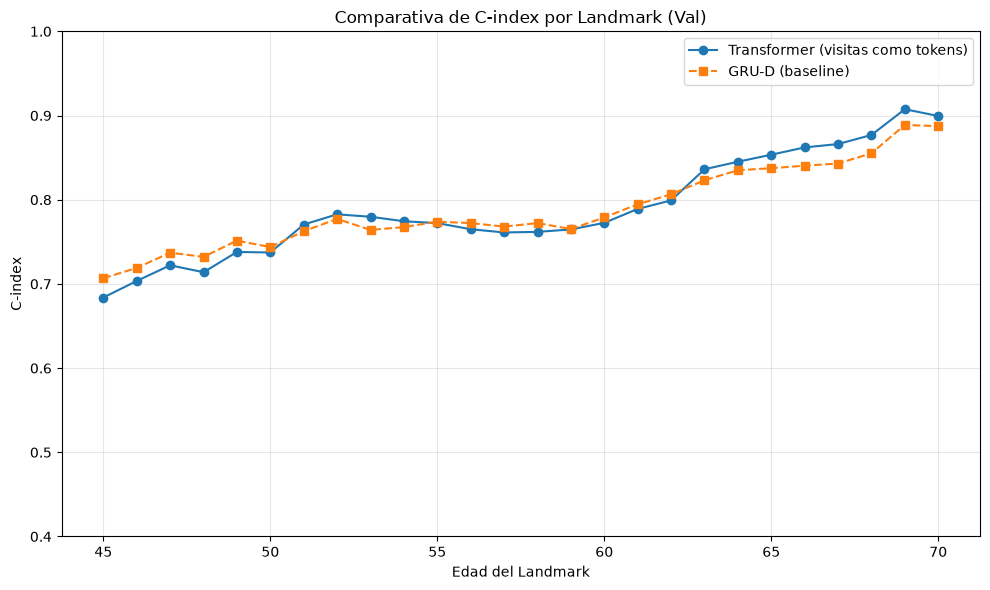


Mean C-index Transformer : 0.7899
Mean C-index GRU-D       : 0.7886
Diferencia (Transformer - GRU-D): +0.0013


In [17]:
import json
import matplotlib.pyplot as plt

# -- Buscar results/metrics/grud.json de forma robusta --
GRUD_METRICS_CANDIDATES = [
    Path.cwd().parent / 'results' / 'metrics' / 'grud.json',         # Local: ejecutando desde sandbox/
    Path.cwd() / 'results' / 'metrics' / 'grud.json',                # Local: ejecutando desde la raiz del repo
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'metrics' / 'grud.json',  # Colab
    DRIVE_BASE / 'results' / 'metrics' / 'grud.json',
    Path('/content/tfm-mulcia-2025-1/results/metrics/grud.json'),
    Path('/content/results/metrics/grud.json'),
]

grud_json_path = next((p.resolve() for p in GRUD_METRICS_CANDIDATES if p.exists()), None)

if grud_json_path is None:
    print('No se encontro results/metrics/grud.json.')
    print(f'Comprueba las rutas candidatas: {GRUD_METRICS_CANDIDATES}')
else:
    with open(grud_json_path, 'r', encoding='utf-8') as f:
        grud_data = json.load(f)
    print(f'Metricas de GRU-D cargadas desde: {grud_json_path}')

    val_landmarks = grud_data.get('c_index', {}).get('val', {}).get('landmarks', {})
    old_ci_list = [val_landmarks.get(str(lm), {}).get('c_index', np.nan) for lm in landmark_times]

    x_tr = landmark_times[:len(ci_list_transformer)]
    x_gr = landmark_times[:len(old_ci_list)]
    
    plt.figure(figsize=(10, 6))
    plt.plot(x_tr, ci_list_transformer, marker='o', label='Transformer (visitas como tokens)')
    plt.plot(x_gr, old_ci_list,          marker='s', linestyle='--', label='GRU-D (baseline)')
    plt.title('Comparativa de C-index por Landmark (Val)')
    plt.xlabel('Edad del Landmark')
    plt.ylabel('C-index')
    plt.grid(True, alpha=0.3)
    plt.ylim(0.4, 1.0)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mean_tr = float(np.nanmean(ci_list_transformer)) if len(ci_list_transformer) > 0 else np.nan
    mean_gr = float(grud_data.get('c_index', {}).get('val', {}).get('mean_c_index', np.nanmean(old_ci_list)))
    diff = mean_tr - mean_gr

    print()
    print(f'Mean C-index Transformer : {mean_tr:.4f}')
    print(f'Mean C-index GRU-D       : {mean_gr:.4f}')
    print(f'Diferencia (Transformer - GRU-D): {diff:+.4f}')
